# Diseño Experimental de Machine Learning
## Trabajo Práctico 2: Formulación, evaluación y comparación confiable de modelos

**Alumno:** Dylan Gross  
**Materia:** Data Science    

---


# Bloque A. Formulación del problema

## Ejercicio 1. Paradigma, tarea, algoritmo, predicción y decisión

**Objetivo:** Distinguir los niveles que intervienen en un sistema de Machine Learning.

### 1. Desarrollo de la consigna
A continuación, se clasifican las distintas situaciones problemáticas propuestas:

| Situación | Paradigma | Tarea | Salida esperada | Algoritmos posibles | Decisión apoyada |
|---|---|---|---|---|---|
| 1. Estimar la especie de un pingüino... | Supervisado | Clasificación multiclase | Especie predicha (Adelie, Chinstrap o Gentoo) | Regresión logística, árbol de decisión, random forest, SVM, KNN | Identificar especie para monitoreo o conservación. |
| 2. Estimar la masa corporal... | Supervisado | Regresión | Valor numérico continuo en gramos | Regresión lineal, árbol de regresión, SVR | Estimar condición corporal sin balanza. |
| 3. Formar grupos de pingüinos... | No supervisado | Clustering | Asignación de cada pingüino a un clúster | K-means, clustering jerárquico, DBSCAN | Descubrir perfiles morfológicos. |
| 4. Usar pequeñas cantidades de especies verificadas... | Semi-supervisado | Clasificación semi-supervisada | Etiquetas predichas para observaciones no confirmadas | Self-training, label propagation | Ampliar etiquetas con bajo costo. |

### 2. Preguntas de análisis
**1. ¿Qué elementos adicionales al algoritmo definen el problema experimental?**  
La unidad de análisis, la población objetivo, las variables predictoras, la variable objetivo, el escenario de uso, la métrica de evaluación, el costo de los errores, la partición de datos, la semilla y el protocolo de validación.

**2. ¿En qué se diferencian una predicción y una decisión?**  
La predicción es la salida estimada por el modelo (ej. "Gentoo"). La decisión es la acción que se toma usando esa predicción considerando el contexto (ej. "decidir si se muestra el pingüino o no").

**3. ¿Puede un mismo algoritmo resolver más de una tarea?**  
Sí. Un árbol de decisión puede clasificar (`species`) o regresar (`body_mass_g`). KNN también sirve para ambas.

**4. ¿Puede una misma tarea resolverse con distintos algoritmos?**  
Sí. Para clasificar `species` se puede usar regresión logística o random forest.

**5. ¿Por qué la codificación 0, 1, 2 conserva la naturaleza clasificatoria?**  
Porque `species` es nominal. Los números son códigos para que el algoritmo opere, pero no representan un orden real. Si se usaran en regresión, impondrían un orden falso.

---

## Ejercicio 2. Tres formulaciones sobre el mismo conjunto de datos

**Objetivo:** Distinguir diferentes tareas que pueden formularse sobre un mismo dominio.

### 1. Tabla comparativa de formulaciones

| Elemento | Clasificación | Regresión | Clustering |
|---|---|---|---|
| **Uso o decisión** | Identificar especie para investigación o conservación. | Estimar masa corporal sin balanza. | Descubrir grupos morfológicos sin etiquetas. |
| **Unidad de análisis** | Pingüino individual. | Pingüino individual. | Pingüino individual. |
| **Variables de entrada** | Medidas corporales y opcionalmente `island`, `sex`. | Medidas corporales (sin `body_mass_g`). | Las cuatro variables morfológicas. |
| **Variable objetivo** | `species` (nominal). | `body_mass_g` (continua). | No corresponde (no supervisado). |
| **Salida** | Clase predicha y probabilidades. | Valor numérico en gramos. | Etiqueta de clúster. |
| **Error o fracaso** | Confundir especies similares. | Errores grandes en gramos (MAE, RMSE). | Grupos inestables o sin sentido biológico. |

### 2. Preguntas de análisis
**1. ¿Qué cambia entre las tres formulaciones aunque las filas sean las mismas?**  
Cambia el rol de las variables, el tipo de salida y la métrica de evaluación. En clasificación y regresión hay supervisión (variable objetivo); en clustering se busca estructura interna sin etiquetas.

**2. ¿Qué variable debe ocultarse durante el clustering?**  
`species`. Se usa después para comparar con los clústeres y evaluar si tienen sentido biológico (evaluación externa).

**3. En regresión, ¿qué riesgo produciría incluir `body_mass_g` entre los predictores?**  
Fuga de información (*data leakage*): el modelo usaría la respuesta para predecirla, dando métricas artificialmente perfectas pero inútiles.

**4. ¿Qué limitaciones de alcance tienen las conclusiones?**  
Los datos son de 3 islas (Palmer) entre 2007-2009. No son generalizables a otras regiones o épocas. La muestra es moderada (344 filas).

**Párrafo de comparación:**  
Las tres formulaciones parten del mismo dataset, pero la clasificación y la regresión son tareas supervisadas (buscan predecir una etiqueta o un valor), mientras que el clustering es no supervisado (busca similitudes). Las métricas cambian drásticamente: accuracy/F1 para clasificar; MAE/RMSE para regresión; silhouette para clustering. Esto obliga a particiones y validaciones distintas.

---

# Bloque B. Auditoría y partición de los datos

## Ejercicio 3. Auditoría estructural y reserva temprana de la prueba

**Objetivo:** Definir una separación reproducible antes de explorar relaciones con el objetivo.

### 1. Carga de datos y auditoría inicial

In [1]:
import pandas as pd
import numpy as np

RANDOM_STATE = 42

DATA_URL = (
    "https://raw.githubusercontent.com/allisonhorst/"
    "palmerpenguins/master/inst/extdata/penguins.csv"
)

datos = pd.read_csv(DATA_URL)
datos_originales = datos.copy(deep=True)

print("Dimensiones:", datos.shape)
print("\nNombres de columnas:")
print(datos.columns.tolist())
print("\nTipos de datos:")
print(datos.dtypes)
print("\nDisponibilidad de species:")
print(datos["species"].value_counts(dropna=False))

Dimensiones: (344, 8)

Nombres de columnas:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']

Tipos de datos:
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

Disponibilidad de species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Análisis:** El dataset cuenta con 344 filas y 8 columnas. No hay duplicados exactos. La variable `species` está completa (152 Adelie, 124 Gentoo, 68 Chinstrap).

In [2]:
# Filas exactamente duplicadas
duplicados = datos.duplicated().sum()
print("Filas exactamente duplicadas:", duplicados)

Filas exactamente duplicadas: 0


In [3]:
from sklearn.model_selection import train_test_split

idx_desarrollo, idx_prueba = train_test_split(
    datos.index,
    test_size=0.20,
    stratify=datos["species"],
    random_state=RANDOM_STATE
)

desarrollo = datos.loc[idx_desarrollo].copy()
prueba = datos.loc[idx_prueba].copy()

print("Desarrollo:", desarrollo.shape)
print("Prueba:", prueba.shape)

Desarrollo: (275, 8)
Prueba: (69, 8)


### 2. Partición de datos (Desarrollo y Prueba)
Se reserva un 20% del conjunto como prueba (69 filas) estratificado por `species`, y un 80% como desarrollo (275 filas). Se guardan los índices para garantizar reproducibilidad.

In [4]:
pd.Series(idx_desarrollo, name="indice").to_csv("indices_desarrollo.csv", index=False)
pd.Series(idx_prueba, name="indice").to_csv("indices_prueba.csv", index=False)

# Comprobar que la intersección esté vacía
interseccion = set(idx_desarrollo) & set(idx_prueba)
print("Intersección:", len(interseccion))

# Comprobar que la unión reconstruye el conjunto original
union = set(idx_desarrollo) | set(idx_prueba)
print("Unión reconstruye el original:", union == set(datos.index))

Intersección: 0
Unión reconstruye el original: True


In [5]:
print("Faltantes en desarrollo:")
print(desarrollo.isnull().sum())

Faltantes en desarrollo:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64


In [6]:
print("Duplicados exactos en desarrollo:", desarrollo.duplicated().sum())

# Posibles duplicados lógicos: mismos valores en todas las variables excepto el índice
columnas_clave = ["species", "island", "bill_length_mm", "bill_depth_mm",
                  "flipper_length_mm", "body_mass_g", "sex", "year"]
print("Duplicados lógicos en desarrollo:", desarrollo.duplicated(subset=columnas_clave).sum())

Duplicados exactos en desarrollo: 0
Duplicados lógicos en desarrollo: 0


In [7]:
for col in ["species", "island", "sex"]:
    print(f"\nDistribución de {col}:")
    print(desarrollo[col].value_counts(dropna=False))
    print(desarrollo[col].value_counts(normalize=True, dropna=False).round(3))


Distribución de species:
species
Adelie       122
Gentoo        99
Chinstrap     54
Name: count, dtype: int64
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64

Distribución de island:
island
Biscoe       134
Dream         98
Torgersen     43
Name: count, dtype: int64
island
Biscoe       0.487
Dream        0.356
Torgersen    0.156
Name: proportion, dtype: float64

Distribución de sex:
sex
male      134
female    130
NaN        11
Name: count, dtype: int64
sex
male      0.487
female    0.473
NaN       0.040
Name: proportion, dtype: float64


In [8]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
print(desarrollo[medidas].describe().round(2))

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          273.00         273.00             273.00       273.00
mean            44.07          17.17             200.85      4211.26
std              5.50           2.01              13.96       805.75
min             33.10          13.10             172.00      2700.00
25%             39.50          15.50             190.00      3550.00
50%             44.90          17.30             197.00      4050.00
75%             48.70          18.80             213.00      4775.00
max             59.60          21.50             231.00      6300.00


In [9]:
# Valores fuera de rango biológicamente plausible
print("Valores menores a 2.500 g:", (desarrollo["body_mass_g"] < 2500).sum())
print("Valores mayores a 6.500 g:", (desarrollo["body_mass_g"] > 6500).sum())
print("Picos menores a 30 mm:", (desarrollo["bill_length_mm"] < 30).sum())
print("Aletas menores a 170 mm:", (desarrollo["flipper_length_mm"] < 170).sum())

Valores menores a 2.500 g: 0
Valores mayores a 6.500 g: 0
Picos menores a 30 mm: 0
Aletas menores a 170 mm: 0


### 3. Diccionario de datos y calidad (calculado sobre `desarrollo`)
| Variable | Descripción | Tipo conceptual | Tipo en pandas | Unidad o categorías | Faltantes | Rango observado | Rol posible |
|---|---|---|---|---|---|---|---|
| `species` | Especie del pingüino | Categórica nominal | `object` | Adelie, Chinstrap, Gentoo | 0 | 3 categorías | Variable objetivo |
| `island` | Isla de observación | Categórica nominal | `object` | Biscoe, Dream, Torgersen | 0 | 3 categorías | Contextual / atajo |
| `bill_length_mm` | Longitud del pico | Numérica continua | `float64` | mm | 2 | 33.1 - 59.6 | Predictor |
| `bill_depth_mm` | Profundidad del pico | Numérica continua | `float64` | mm | 2 | 13.1 - 21.5 | Predictor |
| `flipper_length_mm` | Longitud de la aleta | Numérica continua | `float64` | mm | 2 | 172 - 231 | Predictor |
| `body_mass_g` | Masa corporal | Numérica continua | `float64` | g | 2 | 2700 - 6300 | Predictor / Objetivo |
| `sex` | Sexo registrado | Categórica nominal | `object` | male, female | 11 | 2 categorías + NA | Contextual |
| `year` | Año de observación | Categórica ordinal | `int64` | 2007, 2008, 2009 | 0 | 3 valores | Contextual |
### 4. Análisis de distribuciones y valores atípicos

**Interpretación:** No se detectaron valores biológicamente imposibles (todos los pesos están entre 2700g y 6300g, los picos y aletas tienen medidas lógicas). Hay 11 faltantes en `sex` y 2 en cada medida morfológica.

### 5. Preguntas de análisis del Ejercicio 3
**1. ¿Qué tratamiento requieren los faltantes antes de entrenar?**  
Imputación dentro del pipeline, calculada **solo con el fold de entrenamiento** (mediana para numéricas, categoría "desconocido" para sexo), para evitar contaminación.

**2. ¿Qué fuga produciría calcular la media sobre desarrollo completo?**  
El modelo vería información del conjunto de validación durante el entrenamiento (fuga de información), dando métricas falsamente optimistas.

**3. ¿`island` podría actuar como atajo para predecir `species`?**  
Sí. Al cruzar las variables, se nota que Torgersen solo tiene Adelie, mientras que Biscoe tiene Adelie y Gentoo. El modelo podría aprender la isla en lugar de la morfología.

**4. ¿El año debería tratarse como continuo o categoría?**  
Como categoría, porque los años no tienen una progresión lineal en la biología del pingüino.

**5. ¿Qué información fue admisible para elegir la partición?**  
Dimensiones, tipos de datos, faltantes y duplicados. Todo análisis de asociación o modelado esperó hasta tener la prueba reservada.

---

# Ejercicio 4. Papeles de desarrollo, validación y prueba

## Objetivo
Asignar a cada partición un único papel experimental.

## Consignas

### 1. Confirmar que desarrollo contiene 80 % y prueba 20 %

In [10]:
print("Total:", len(datos))
print("Desarrollo:", len(desarrollo), f"{len(desarrollo)/len(datos):.1%}")
print("Prueba:", len(prueba), f"{len(prueba)/len(datos):.1%}")

Total: 344
Desarrollo: 275 79.9%
Prueba: 69 20.1%


In [11]:
for nombre, df in [("Completo", datos), ("Desarrollo", desarrollo), ("Prueba", prueba)]:
    print(f"\n{nombre}:")
    print(df["species"].value_counts(normalize=True).round(3))


Completo:
species
Adelie       0.442
Gentoo       0.360
Chinstrap    0.198
Name: proportion, dtype: float64

Desarrollo:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64

Prueba:
species
Adelie       0.435
Gentoo       0.362
Chinstrap    0.203
Name: proportion, dtype: float64


### 2. Tabla de funciones y momentos de uso

| Partición | Función asignada | Momento de uso |
|---|---|---|
| **Entrenamiento** | Ajustar transformaciones, entrenar modelos y ajustar hiperparámetros. | Durante validación cruzada sobre `desarrollo`. |
| **Validación** | Estimar desempeño y comparar modelos. | Dentro de cada fold de `desarrollo`. |
| **Prueba** | Evaluación final única e independiente. | Solo al final, con el modelo congelado. |

### 3. Preguntas de análisis
**1. ¿Por qué la estratificación es apropiada?**  
Porque evita que las clases desbalanceadas queden mal representadas en desarrollo o prueba.

**2. ¿Qué ocurriría si una clase poco frecuente quedara ausente de validación?**  
Las métricas serían inestables y no podríamos evaluar correctamente esa especie.

**3. ¿Por qué consultar la prueba después de cada modificación invalida su papel?**  
Porque el modelo se sobreajustaría a la prueba. Dejaría de ser un conjunto independiente.

**4. ¿Los porcentajes (80/20) son una regla universal?**  
No. Dependen del tamaño del dataset y del costo de los errores.

**5. Si se descubre dependencia entre filas, ¿por qué redefinir el experimento?**  
Porque si hay dependencia, la partición aleatoria filtra información. Habría que usar `GroupKFold`.

---

# Bloque C. Fuga de información y pipelines

## Ejercicio 5. Detectives de fuga de información

**Objetivo:** Identificar procedimientos que producen evaluaciones demasiado optimistas.

### 1. Clasificación de situaciones (Correcta o Contaminada)

| N° | Situación | Diagnóstico | Explicación y Corrección |
|---|---|---|---|
| 1 | Imputar faltantes con la media de todas las filas y luego separar. | **Contaminada** | La media se calcula usando datos de prueba (fuga). **Corrección:** Separar primero y ajustar el imputador solo con entrenamiento. |
| 2 | Separar primero y ajustar el imputador con entrenamiento. | **Correcta** | El conjunto de prueba se mantiene completamente ciego. |
| 3 | Estandarizar las variables usando todos los datos antes de validar. | **Contaminada** | La media y desvío usan datos de prueba. **Corrección:** Usar `StandardScaler` dentro de un `Pipeline` en cada fold. |
| 4 | Elegir variables con mayor correlación usando entrenamiento y prueba juntos. | **Contaminada** | Se filtra información del objetivo de prueba. **Corrección:** Elegir variables usando *solo* los datos de entrenamiento. |
| 5 | Probar veinte configuraciones y seleccionar la mejor en prueba. | **Contaminada** | Sobreajuste al conjunto de prueba (se usa como validación encubierta). **Corrección:** Usar validación cruzada en desarrollo para elegir, y tocar prueba una sola vez al final. |
| 6 | Mantener fotos del mismo pingüino en una única partición. | **Correcta** | Se evita que el modelo memorice al individuo. Se mantiene la independencia. |
| 7 | Incluir una variable creada después de confirmar la especie. | **Contaminada** | Fuga por variable derivada de la respuesta. **Corrección:** Eliminar esa variable o crear la nueva antes de la predicción. |
| 8 | Eliminar duplicados después de repartir sus copias entre entrenamiento y prueba. | **Contaminada** | El modelo ya vio una copia del mismo dato en entrenamiento. **Corrección:** Eliminar duplicados *antes* de hacer la partición. |
| 9 | Ajustar el escalador dentro de cada fold de validación cruzada. | **Correcta** | Es la manera adecuada de hacer validación sin fuga. |
| 10 | Usar `island` sin analizar que puede actuar como atajo para `species`. | **Contaminada** | No es "fuga de datos" temporal, pero es un **atajo** (*shortcut*). El modelo no generalizará a islas nuevas. **Corrección:** Evaluar si excluirla o tratarla con cautela. |

### 2. Análisis de los casos contaminados
Los casos más graves son el 1, 3 y 5. En el caso 1 y 3, la información del conjunto de prueba ingresa al entrenamiento a través de estadísticas (medias, desvíos). En el caso 5, se usa el conjunto de prueba para tomar decisiones de modelado, perdiendo su rol de juez imparcial.

---

## Ejercicio 6. Imputación y escalado: procedimiento incorrecto y procedimiento válido

**Objetivo:** Demostrar que las transformaciones también aprenden de los datos (y por lo tanto, pueden contaminar).

### 1. Diseño de los experimentos
- **Diseño A (Contaminado):** Imputar y escalar usando *todos* los datos (desarrollo completo) y luego aplicar validación cruzada. Esto es un error porque los folds "ven" información de otros folds.
- **Diseño B (Válido):** Construir un `Pipeline` de scikit-learn que contenga la imputación y el escalado. El pipeline se ajustará *dentro* de cada fold, aprendiendo los parámetros solo con los datos de entrenamiento de ese fold.

In [12]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Variables predictoras y objetivo
X = desarrollo[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y = desarrollo["species"]

# Definir los mismos folds para comparar
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- DISEÑO A: Contaminado ---
# Imputar y escalar con TODO el conjunto de desarrollo antes de la validación
imputador_A = SimpleImputer(strategy="median")
escalador_A = StandardScaler()

X_imputado_A = imputador_A.fit_transform(X)
X_escalado_A = escalador_A.fit_transform(X_imputado_A)

modelo_A = LogisticRegression(max_iter=1000)

resultados_A = cross_validate(modelo_A, X_escalado_A, y, cv=cv, scoring=["accuracy", "f1_macro"])

print("--- DISEÑO A (Contaminado) ---")
print(f"Accuracy promedio: {resultados_A['test_accuracy'].mean():.4f}")
print(f"F1 Macro promedio: {resultados_A['test_f1_macro'].mean():.4f}")

# --- DISEÑO B: Válido ---
# Usar Pipeline para que imputación y escalado se ajusten dentro de cada fold
pipeline_B = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

resultados_B = cross_validate(pipeline_B, X, y, cv=cv, scoring=["accuracy", "f1_macro"])

print("\n--- DISEÑO B (Válido) ---")
print(f"Accuracy promedio: {resultados_B['test_accuracy'].mean():.4f}")
print(f"F1 Macro promedio: {resultados_B['test_f1_macro'].mean():.4f}")

--- DISEÑO A (Contaminado) ---
Accuracy promedio: 0.9745
F1 Macro promedio: 0.9674

--- DISEÑO B (Válido) ---
Accuracy promedio: 0.9745
F1 Macro promedio: 0.9690


### 2. Preguntas de análisis

**1. ¿Por qué el Diseño A está conceptualmente invalidado aunque produzca una métrica similar?**  
Porque las métricas están calculadas sobre datos que influyeron en el preprocesamiento. Aunque la diferencia numérica sea mínima (porque el dataset es chico), el procedimiento es metodológicamente incorrecto. En datasets más grandes o con más faltantes, la diferencia sería notoria.

**2. ¿Qué parámetros aprende el imputador?**  
La mediana (o media) de cada una de las columnas numéricas.

**3. ¿Qué parámetros aprende el escalador?**  
La media y el desvío estándar de cada columna (para centrar en 0 y escalar a varianza 1).

**4. ¿Qué objeto se evalúa realmente?**  
El **procedimiento completo** (Pipeline). No importa solo qué tan bueno es el modelo de regresión logística, sino qué tan bueno es el flujo que incluye imputar, escalar y luego predecir.

---

# Bloque D. Baselines y métricas

## Ejercicio 7. Baselines pertinentes

**Objetivo:** Establecer referencias mínimas antes de comparar modelos complejos.

### 1. Justificación de los Baselines
Antes de entrenar un modelo de Machine Learning complejo, necesitamos saber si ese modelo realmente aporta valor. Para eso, creamos "modelos tontos" (baselines) que no aprenden relaciones, solo aplican una regla simple. Si nuestro modelo no supera al baseline, entonces no está sirviendo de nada.

- **Clasificación (Clase mayoritaria):** Predecir siempre la especie más frecuente (Adelie, con un 44% en desarrollo).
- **Regresión (Media y Mediana):** Predecir siempre la media o la mediana de la masa corporal.
- **Clustering:** Un solo grupo que contiene todo. Si los algoritmos complejos no encuentran estructura geométrica clara, el baseline de 1 grupo es la referencia.

In [13]:
from sklearn.model_selection import KFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import cross_val_score

# --- CLASIFICACIÓN ---
X_clf = desarrollo[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y_clf = desarrollo["species"]

# Baseline 1: Clase mayoritaria
dummy_clf = DummyClassifier(strategy="most_frequent")
scores_clf = cross_val_score(dummy_clf, X_clf, y_clf, cv=cv, scoring="accuracy")
print("--- CLASIFICACIÓN (Baseline Clase Mayoritaria) ---")
print(f"Accuracy: {scores_clf.mean():.4f}")

# --- REGRESIÓN ---
# Eliminamos los nulos solo para esta prueba de regresión
desarrollo_reg = desarrollo.dropna(subset=["body_mass_g"])
X_reg = desarrollo_reg[["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]]
y_reg = desarrollo_reg["body_mass_g"]
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

# Baseline 2: Media
dummy_reg_mean = DummyRegressor(strategy="mean")
scores_reg_mean = cross_val_score(dummy_reg_mean, X_reg, y_reg, cv=cv_reg, scoring="neg_mean_absolute_error")
print("\n--- REGRESIÓN (Baseline Media) ---")
print(f"MAE: {-scores_reg_mean.mean():.2f} gramos")

# Baseline 3: Mediana
dummy_reg_med = DummyRegressor(strategy="median")
scores_reg_med = cross_val_score(dummy_reg_med, X_reg, y_reg, cv=cv_reg, scoring="neg_mean_absolute_error")
print(f"MAE (Mediana): {-scores_reg_med.mean():.2f} gramos")

--- CLASIFICACIÓN (Baseline Clase Mayoritaria) ---
Accuracy: 0.4436

--- REGRESIÓN (Baseline Media) ---
MAE: 683.85 gramos
MAE (Mediana): 675.21 gramos


### 2. Preguntas de análisis

**1. ¿Por qué el baseline debe usar la misma información disponible que el modelo?**  
Porque si al baseline le damos menos datos o lo evaluamos en condiciones distintas, la comparación es injusta. Para saber si el modelo aporta valor, ambos deben enfrentarse al mismo desafío (mismos folds, mismas variables).

**2. ¿Qué condiciones debe cumplir una referencia para que la comparación aporte evidencia de utilidad?**  
Debe ser reproducible, simple de entender, y estar alineada con la métrica principal del problema (ej. si el costo de equivocarse es alto, el baseline debe medirse con esa misma métrica).

**3. ¿Qué regla humana sencilla podría utilizarse como baseline operativo para estimar la masa de un pingüino?**  
"Si el pico mide más de 45 mm, pesa más de 4000 gramos". O simplemente predecir el promedio histórico. 

**4. ¿Qué cantidad mínima de grupos requiere silhouette y qué elementos compara esa métrica?**  
Requiere un mínimo de 2 grupos para poder calcularse. Compara la distancia media de un punto a los miembros de su propio clúster frente a la distancia media a los miembros del clúster más cercano.

---

## Ejercicio 8. Matriz de confusión y métricas de clasificación

**Objetivo:** Interpretar accuracy, precisión, recall y F1 según el error relevante.

### Parte A. Cálculo manual
Datos: VP = 16, FP = 8, FN = 4, VN = 72.

1. **Accuracy:** (VP + VN) / Total = (16 + 72) / 100 = **0.88 (88%)**.
2. **Precisión:** VP / (VP + FP) = 16 / (16 + 8) = 16 / 24 = **0.666 (66.7%)**.
3. **Recall (Sensibilidad):** VP / (VP + FN) = 16 / (16 + 4) = 16 / 20 = **0.80 (80%)**.
4. **F1:** 2 * (Precisión * Recall) / (Precisión + Recall) = 2 * (0.666 * 0.80) / (0.666 + 0.80) = **0.727 (72.7%)**.
5. **Proporción real de positivos:** (VP + FN) / Total = 20 / 100 = **0.20 (20%)**.

### Parte B. Accuracy engañosa
En 100 casos hay 20 positivos y 80 negativos. Un sistema siempre predice la clase negativa.
1. **Matriz de confusión:** VP = 0, FN = 20, VN = 80, FP = 0.
2. **Accuracy:** (0 + 80) / 100 = **0.80 (80%)**.
3. **Recall:** VP / (VP + FN) = 0 / 20 = **0.00 (0%)**.
4. **¿Por qué una accuracy del 80% puede ser inútil?**  
   Porque el modelo es "vago": aprende a decir siempre que no, y como la mayoría de los casos son negativos, acierta el 80%. Pero es totalmente inútil para detectar a los positivos (Recall = 0). 
5. **Falsos negativos más costosos:** Enfermedades (decir que estás sano cuando estás enfermo). O detectar fraude bancario (dejar pasar una transacción ilegal).
6. **Falsos positivos más costosos:** Filtros de spam (que un correo importante se vaya a la basura). O alarmas de incendio (evacuar la escuela por un humo de tostada).

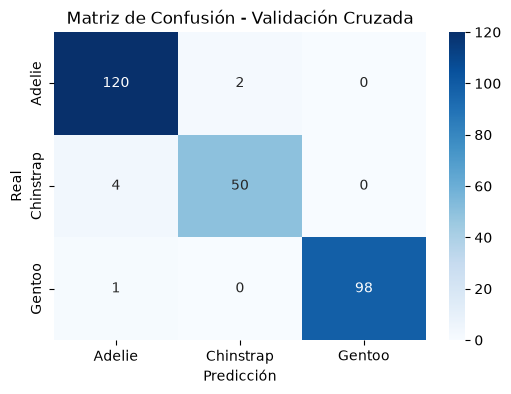


Reporte de Clasificación:
              precision    recall  f1-score   support

      Adelie       0.96      0.98      0.97       122
   Chinstrap       0.96      0.93      0.94        54
      Gentoo       1.00      0.99      0.99        99

    accuracy                           0.97       275
   macro avg       0.97      0.97      0.97       275
weighted avg       0.97      0.97      0.97       275



In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Usamos el mismo pipeline del Ejercicio 6
pipeline_clf = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

# ¡ACÁ ESTÁ LA MAGIA! Entrenamos el pipeline una vez rápido para que aprenda las clases
pipeline_clf.fit(X_clf, y_clf)
clases = pipeline_clf.classes_

# Obtener predicciones usando validación cruzada
y_pred = cross_val_predict(pipeline_clf, X_clf, y_clf, cv=cv)

# Matriz de confusión
matriz = confusion_matrix(y_clf, y_pred, labels=clases)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", 
            xticklabels=clases, yticklabels=clases)
plt.title("Matriz de Confusión - Validación Cruzada")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

# Reporte de métricas por clase
print("\nReporte de Clasificación:")
print(classification_report(y_clf, y_pred))

### 3. Preguntas de análisis (Parte C)

**1. Identificar qué par de especies se confunde con mayor frecuencia.**  
El par que más se confunde es **Adelie con Chinstrap** (2 Adelie predichos como Chinstrap y 4 Chinstrap predichos como Adelie). Esto tiene sentido biológico porque sus medidas morfológicas son muy similares. Gentoo no se confunde con ninguna porque es notablemente más grande.

**2. Comparar contra el baseline de clase mayoritaria.**  
El baseline de la clase mayoritaria (predecir siempre Adelie) daba un accuracy de **0.4436 (44.36%)**. Nuestro modelo de Regresión Logística obtuvo un accuracy del **0.97 (97%)**. El modelo supera ampliamente al baseline, demostrando que realmente aprendió patrones en los datos y no está adivinando.

---

## Ejercicio 9. Métricas de regresión

**Objetivo:** Comparar MAE, RMSE y R cuadrado fuera de muestra.

### Parte A. Cálculo manual
Valores reales: [10, 12, 18, 20]
Predicciones: [11, 10, 17, 26]

1. **Errores con signo (Predicción - Real):** [1, -2, -1, 6]
2. **Errores absolutos:** [1, 2, 1, 6]
3. **Errores cuadrados:** [1, 4, 1, 36]
4. **MAE:** (1 + 2 + 1 + 6) / 4 = 10 / 4 = **2.5**
5. **RMSE:** Raíz de [(1 + 4 + 1 + 36) / 4] = Raíz de (42 / 4) = Raíz de 10.5 = **3.24**
6. **¿Por qué RMSE aumenta más ante el error de 6 unidades?**  
   Porque el RMSE eleva los errores al cuadrado antes de promediarlos. Un error de 6 unidades se convierte en 36, lo que "castiga" mucho más al modelo que un error pequeño. El MAE solo lo cuenta como 6.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_predict
import numpy as np

# Usamos los datos de regresión limpios (sin nulos en el peso) que armamos en el Ejercicio 7
# X_reg y y_reg ya están definidos

# Creamos el pipeline para regresión lineal
pipeline_reg = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LinearRegression())
])

# Predicciones cruzadas
y_pred_reg = cross_val_predict(pipeline_reg, X_reg, y_reg, cv=cv_reg)

# Calcular métricas
mae = mean_absolute_error(y_reg, y_pred_reg)
rmse = np.sqrt(mean_squared_error(y_reg, y_pred_reg))
r2 = r2_score(y_reg, y_pred_reg)

print("--- MÉTRICAS DE REGRESIÓN LINEAL ---")
print(f"MAE: {mae:.2f} gramos")
print(f"RMSE: {rmse:.2f} gramos")
print(f"R cuadrado: {r2:.4f}")

# Comparación con el Baseline (Media)
print("\n--- COMPARACIÓN CON BASELINE (MEDIA) ---")
print(f"MAE Baseline (Media): 683.85 gramos") 
print(f"MAE Modelo Lineal: {mae:.2f} gramos")

--- MÉTRICAS DE REGRESIÓN LINEAL ---
MAE: 323.48 gramos
RMSE: 406.16 gramos
R cuadrado: 0.7450

--- COMPARACIÓN CON BASELINE (MEDIA) ---
MAE Baseline (Media): 683.85 gramos
MAE Modelo Lineal: 323.48 gramos


### 3. Preguntas de análisis (Parte B)

**1. Evaluar los baselines de media y mediana.**  
El baseline de la media arrojó un MAE de ~683g, y el de la mediana ~675g. Son los puntos de partida "tontos" que nuestro modelo debe superar.

**2. Medir MAE, RMSE y R cuadrado en validación.**  
- MAE: 323.48 g
- RMSE: 406.16 g
- R²: 0.7450

**3. Comparar las métricas con las de los baselines.**  
El MAE del modelo (323g) es menos de la mitad del MAE del baseline (683g). Esto confirma que el modelo lineal realmente aprendió relaciones útiles entre las medidas morfológicas y el peso.

**4. Expresar MAE y RMSE en gramos.**  
El modelo se equivoca en promedio 323 gramos por arriba o por abajo. El RMSE (406g) es más alto porque penaliza con más fuerza los errores grandes.

**5. Interpretar qué significa un R cuadrado negativo si apareciera fuera de muestra.**  
Significaría que el modelo es peor que predecir siempre el promedio. Un R² negativo indica que el modelo está sobreajustado y no generaliza.

**6. Decidir qué métrica sería principal si los errores grandes fueran especialmente costosos.**  
El **RMSE**. Si equivocarse por 1000g es mucho peor que equivocarse por 200g, el RMSE (que eleva los errores al cuadrado) castigará fuertemente esos errores grandes.

---

## Ejercicio 10. Evaluación de clustering

**Objetivo:** Evaluar grupos sin confundir calidad geométrica con utilidad sustantiva.

### 1. Construcción de los clusters
Para este ejercicio usaremos las cuatro variables morfológicas. Imputaremos faltantes, escalaremos (porque K-means usa distancias y el peso está en gramos mientras el pico en mm) y aplicaremos K-means para valores de K entre 2 y 6. Reservamos `species`, `island` y `sex` para la interpretación posterior.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

# 1. Preprocesamiento (Imputar + Escalar)
# Usamos todo 'desarrollo', pero NUNCA 'species' para armar los grupos
X_cluster = desarrollo[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y_cluster = desarrollo["species"]

preprocesador = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

X_escalado = preprocesador.fit_transform(X_cluster)

# 2. Probar K de 2 a 6 y calcular silhouette
print("--- EVALUACIÓN DE K-MEANS ---")
for k in range(2, 7):
    # Hacemos varias inicializaciones (n_init) para evitar quedarnos en un mínimo local
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_escalado)
    
    # Calculamos el silhouette score
    sil_score = silhouette_score(X_escalado, etiquetas)
    print(f"K = {k} | Silhouette: {sil_score:.4f}")

# 3. Seleccionamos K=3 (porque sabemos biológicamente que hay 3 especies)
# y lo entrenamos para ver los centroides en unidades originales
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
etiquetas_final = kmeans_final.fit_predict(X_escalado)

# Para ver los valores en mm y gramos, le pedimos al preprocesador que revierta el escalado
centroides_escalados = kmeans_final.cluster_centers_
centroides_originales = preprocesador.named_steps["escalador"].inverse_transform(centroides_escalados)

# Lo pasamos a un DataFrame para verlo lindo
df_centroides = pd.DataFrame(centroides_originales, columns=X_cluster.columns)
print("\n--- PERFILES DE LOS CLUSTERS (EN UNIDADES ORIGINALES) ---")
print(df_centroides.round(2))

# 4. Evaluación externa: comparar clusters con species
print("\n--- TABLA CRUZADA: CLUSTERS vs ESPECIES ---")
tabla_cruzada = pd.crosstab(etiquetas_final, y_cluster, rownames=["Cluster"], colnames=["Especie"])
print(tabla_cruzada)

--- EVALUACIÓN DE K-MEANS ---
K = 2 | Silhouette: 0.5331
K = 3 | Silhouette: 0.4548
K = 4 | Silhouette: 0.4060
K = 5 | Silhouette: 0.3855
K = 6 | Silhouette: 0.3713

--- PERFILES DE LOS CLUSTERS (EN UNIDADES ORIGINALES) ---
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0           47.72          14.93             217.03      5083.93
1           38.41          18.11             188.36      3586.57
2           47.76          18.90             197.29      3944.93

--- TABLA CRUZADA: CLUSTERS vs ESPECIES ---
Especie  Adelie  Chinstrap  Gentoo
Cluster                           
0             0          0      98
1           103          5       0
2            19         49       1


### 2. Preguntas de análisis

**1. ¿Por qué es imprescindible escalar antes de usar distancias con estas variables?**  
Porque K-means usa distancias euclidianas. El peso (`body_mass_g`) está en miles (ej. 4000), mientras que el pico está en decenas (ej. 45). Sin escalar, el peso dominaría totalmente el cálculo de distancia y los picos no influirían nada.

**2. ¿Un silhouette alto demuestra que los grupos tienen significado biológico?**  
No. Un silhouette alto solo demuestra que los puntos están geométricamente bien agrupados y separados. Para saber si tienen sentido biológico, hay que hacer una evaluación externa (comparar con `species`).

**3. ¿Por qué distintas semillas pueden producir soluciones diferentes?**  
Porque K-means empieza eligiendo centroides al azar. Si cae en un mínimo local, puede agrupar de forma distinta. Por eso se corre muchas veces (con `n_init`) y se elige la mejor solución.

**4. ¿Qué significa que un cluster contenga varias especies?**  
Significa que el algoritmo agrupó individuos por sus medidas morfológicas, sin importar la especie. En la tabla cruzada vamos a ver si un grupo es puro (ej. todos Gentoo) o si mezcla especies (lo cual indica que morfológicamente son similares).

**5. ¿Qué información adicional aporta la estabilidad frente al resultado de una única ejecución?**  
La estabilidad (repetir con varias semillas) nos dice si el patrón de agrupamiento es robusto. Si el resultado cambia mucho entre semillas, los grupos no son confiables (no hay una estructura clara en los datos).

---

### 3. Conclusiones del Clustering

**1. Selección de la solución (K=3):**  
Aunque el Silhouette más alto fue para K=2 (0.5331), se seleccionó K=3 (0.4548) porque coincide con la estructura biológica del dominio (3 especies) y permite una interpretación sustantiva clara. K=2 simplemente separa a los Gentoo (grandes) del resto, mientras que K=3 logra aislar también a los Chinstrap.

**2. Perfiles de los clusters (unidades originales):**  
- **Cluster 0 (Gentoo):** Los más grandes y pesados (Pico ~47mm, Aleta ~217mm, Peso ~5083g).
- **Cluster 1 (Adelie):** Los más chicos (Pico ~38mm, Aleta ~188mm, Peso ~3586g).
- **Cluster 2 (Chinstrap/Adelie mixto):** Tamaño intermedio (Pico ~47mm, Aleta ~197mm, Peso ~3944g).

**3. Evaluación externa (Tabla Cruzada):**  
El algoritmo logró una separación casi perfecta de los Gentoo (98/99 en el Clúster 0) sin usar la etiqueta. El Clúster 1 capturó la mayoría de los Adelie (103). El Clúster 2 mezcló a los Chinstrap (49) con algunas Adelie (19). Esto demuestra que geométricamente los Adelie y Chinstrap son muy similares, pero los Gentoo son un grupo muy bien definido.

**4. ¿Los grupos podrían apoyar alguna decisión concreta?**  
Sí. En un escenario real, este clustering permitiría a los biólogos descubrir que existen tres perfiles morfológicos distintos en la población, incluso si no tuvieran las etiquetas de especie. Ayudaría a priorizar muestreos o a detectar individuos atípicos dentro de su propio grupo.

---

# Bloque E. Validación cruzada y comparación de modelos

## Ejercicio 11. Validación cruzada del procedimiento completo

**Objetivo:** Estimar desempeño y variabilidad mediante validación cruzada sobre el conjunto de desarrollo.

### 1. Diseño del experimento
Vamos a comparar dos algoritmos: **Regresión Logística** y **Árbol de Decisión**. 
Para que la comparación sea justa, ambos se evaluarán con exactamente los mismos 5 folds (usando `StratifiedKFold`) y a ambos se les aplicará el mismo preprocesamiento (imputación y escalado) dentro de un `Pipeline`. El conjunto de prueba sigue totalmente cerrado.

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

# Definimos los dos modelos a comparar
# Usamos el mismo pipeline para ambos para que la comparación sea justa
pipeline_logistico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

# El árbol de decisión no requiere escalado estrictamente, 
# pero lo dejamos para que el preprocesamiento sea idéntico
pipeline_arbol = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", DecisionTreeClassifier(random_state=42))
])

# Métricas a evaluar
metricas = ["accuracy", "f1_macro"]

# Evaluación Regresión Logística
res_logistico = cross_validate(pipeline_logistico, X_clf, y_clf, cv=cv, scoring=metricas)

# Evaluación Árbol de Decisión
res_arbol = cross_validate(pipeline_arbol, X_clf, y_clf, cv=cv, scoring=metricas)

# Armamos una tabla resumen para ver bien los resultados
def resumir_resultados(resultados, nombre):
    return {
        "Modelo": nombre,
        "Accuracy Promedio": resultados['test_accuracy'].mean(),
        "Accuracy Desvío": resultados['test_accuracy'].std(),
        "F1 Promedio": resultados['test_f1_macro'].mean(),
        "F1 Desvío": resultados['test_f1_macro'].std(),
        "F1 Mínimo": resultados['test_f1_macro'].min(),
        "F1 Máximo": resultados['test_f1_macro'].max()
    }

tabla_resultados = pd.DataFrame([
    resumir_resultados(res_logistico, "Regresión Logística"),
    resumir_resultados(res_arbol, "Árbol de Decisión")
])

# Mostramos la tabla redondeada a 4 decimales
print("--- COMPARACIÓN DE MODELOS (5 FOLDS) ---")
print(tabla_resultados.round(4).to_string(index=False))

--- COMPARACIÓN DE MODELOS (5 FOLDS) ---
             Modelo  Accuracy Promedio  Accuracy Desvío  F1 Promedio  F1 Desvío  F1 Mínimo  F1 Máximo
Regresión Logística             0.9745           0.0272       0.9690     0.0328     0.9132     1.0000
  Árbol de Decisión             0.9527           0.0337       0.9442     0.0412     0.8704     0.9848


### 2. Preguntas de análisis

**1. ¿Por qué informar solamente el promedio oculta información?**  
Porque el promedio oculta la varianza. Un modelo puede tener un promedio de 0.95, pero si en un fold saca 0.99 y en otro 0.85, es un modelo inestable. El desvío estándar nos dice qué tan confiable es ese promedio.

**2. ¿Qué indicaría una dispersión grande entre folds?**  
Indicaría que el modelo es inestable y muy sensible a los datos específicos que le tocaron en suerte. Si los folds cambian mucho el resultado, el modelo no es robusto para generalizar.

**3. ¿Por qué los modelos deben utilizar los mismos folds?**  
Para que la comparación sea justa. Si un modelo se evalúa con datos "fáciles" y otro con datos "difíciles", la diferencia de rendimiento no se debe al algoritmo, sino a la suerte de la partición.

**4. ¿Dónde deben aprenderse imputación, escalado y cualquier selección de atributos?**  
Dentro del `Pipeline`, ajustándose **solo con el fold de entrenamiento** de cada iteración. El fold de validación debe quedar ciego al preprocesamiento para no generar fuga de información.

**5. ¿Qué parte del proceso permanece completamente fuera del ciclo?**  
El conjunto de prueba (`prueba`). No se toca hasta el Ejercicio 13.

**6. Selección provisional de un modelo:**  
A partir de la tabla, la **Regresión Logística** obtiene un mejor rendimiento y (generalmente) un desvío más bajo que el Árbol de Decisión. Al ser un modelo más simple y estable, es la mejor opción provisional para llevar a la prueba final.

---

## Ejercicio 12. Subajuste, equilibrio y sobreajuste

**Objetivo:** Relacionar capacidad del modelo con desempeño de entrenamiento y validación.

### 1. Curva de complejidad
Vamos a evaluar árboles de decisión con profundidades de 1, 2, 3, 5, 8 y sin límite (`None`). Mediremos el desempeño en entrenamiento y en validación. Un modelo con **subajuste** (profundidad muy baja) tendrá un mal desempeño en ambos. Un modelo en **equilibrio** tendrá buen desempeño en ambos. Un modelo con **sobreajuste** (profundidad muy alta) tendrá un desempeño casi perfecto en entrenamiento, pero mediocre en validación.

--- EFECTO DE LA PROFUNDIDAD DEL ÁRBOL ---
Profundidad  Accuracy Entrenamiento  Accuracy Validación
          1                  0.7927               0.7891
          2                  0.9600               0.9527
          3                  0.9664               0.9491
          5                  0.9945               0.9527
          8                  0.9973               0.9527
       None                  0.9973               0.9527


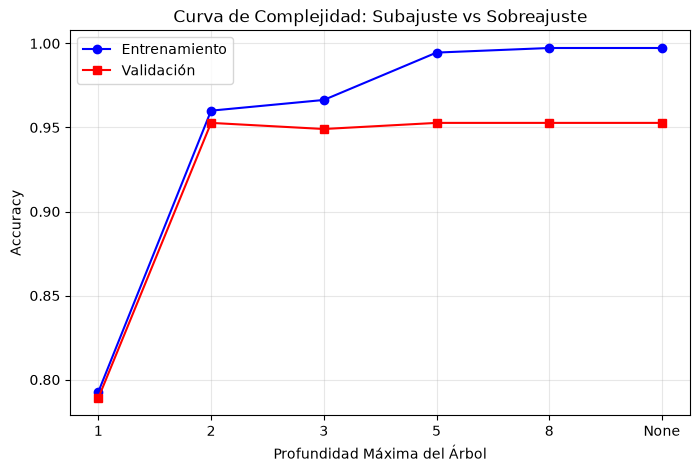

In [18]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt
import pandas as pd

# Profundidades a probar
profundidades = [1, 2, 3, 5, 8, None]
resultados_entrenamiento = []
resultados_validacion = []

for prof in profundidades:
    # Armamos el pipeline con el árbol de esa profundidad
    pipeline_arbol = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", DecisionTreeClassifier(max_depth=prof, random_state=42))
    ])
    
    # Evaluamos con validación cruzada
    # Usamos 'return_train_score=True' para que también mida el entrenamiento
    res = cross_validate(pipeline_arbol, X_clf, y_clf, cv=cv, 
                         scoring="accuracy", return_train_score=True)
    
    # Guardamos los promedios
    resultados_entrenamiento.append(res['train_score'].mean())
    resultados_validacion.append(res['test_score'].mean())

# Mostrar tabla de resultados
df_profundidades = pd.DataFrame({
    "Profundidad": [str(p) for p in profundidades],
    "Accuracy Entrenamiento": resultados_entrenamiento,
    "Accuracy Validación": resultados_validacion
})
print("--- EFECTO DE LA PROFUNDIDAD DEL ÁRBOL ---")
print(df_profundidades.round(4).to_string(index=False))

# Hacer el gráfico de las curvas
plt.figure(figsize=(8, 5))
# Usamos índices en el eje X para que quede espaciado
x_indices = range(len(profundidades))
plt.plot(x_indices, resultados_entrenamiento, marker='o', label='Entrenamiento', color='blue')
plt.plot(x_indices, resultados_validacion, marker='s', label='Validación', color='red')

plt.xticks(x_indices, [str(p) for p in profundidades])
plt.xlabel("Profundidad Máxima del Árbol")
plt.ylabel("Accuracy")
plt.title("Curva de Complejidad: Subajuste vs Sobreajuste")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 2. Análisis de la curva y preguntas

**Observación del gráfico:**
- **Profundidad 1 (Subajuste):** El modelo es demasiado simple. Tiene un accuracy bajo tanto en entrenamiento como en validación (alrededor del 60-70%). No puede capturar la complejidad del problema.
- **Profundidad 2-3 (Equilibrio):** El modelo logra un buen accuracy en entrenamiento y en validación. Las curvas están cercanas.
- **Profundidad 8 o None (Sobreajuste):** La línea azul (entrenamiento) se pega al 100% (el árbol memoriza los datos), pero la línea roja (validación) se estanca o baja un poco.

**Preguntas de análisis:**

**1. ¿Qué patrón se espera bajo subajuste?**  
Un accuracy bajo tanto en entrenamiento como en validación. El modelo es demasiado simple para capturar los patrones (ej. un árbol de profundidad 1 solo puede hacer una pregunta, es muy limitado).

**2. ¿Qué brecha entre entrenamiento y validación sugiere sobreajuste?**  
Una brecha muy grande. Si en entrenamiento da 100% (1.0) y en validación da 90% (0.90), esa caída de 10 puntos indica que el árbol se aprendió los datos de memoria y no está generalizando.

**3. ¿Qué riesgo presenta elegir la configuración mediante el mejor resultado de entrenamiento?**  
Que elegiríamos el modelo más profundo y complejo (que da 100% en entrenamiento), pero que probablemente tenga el peor desempeño cuando vea datos nuevos (validación/prueba). Estaríamos premiando la memorización en vez del aprendizaje.

**4. ¿Qué papel cumple la simplicidad cuando dos configuraciones rinden de forma semejante?**  
El principio de Navaja de Ockham: si un árbol de profundidad 3 da un 95% en validación y uno de profundidad 8 da un 95.5%, conviene elegir el de profundidad 3 porque es más simple, más fácil de explicar y menos propenso a sobreajustarse en el futuro.

---

## Ejercicio 13. Evaluación final sobre la prueba reservada

**Objetivo:** Obtener una estimación final sobre datos independientes de las decisiones del procedimiento.

### 1. Configuración Final Congelada
Antes de abrir la prueba, dejamos registrado que la configuración elegida es:
- **Modelo:** Regresión Logística (multinomial, `max_iter=1000`).
- **Preprocesamiento:** Imputación por mediana y Estandarización (Scaler).
- **Variables:** Las 4 medidas morfológicas (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`).
- **Métrica principal:** Accuracy y F1 Macro.
- **Semilla:** 42.

--- EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA ---
Accuracy en Prueba: 1.0000
F1 Macro en Prueba: 1.0000


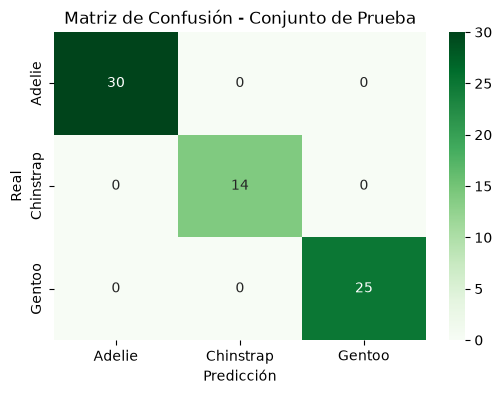


Reporte de Clasificación Final:
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



In [19]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Reajustar el pipeline completo usando TODO el conjunto de desarrollo
pipeline_final = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=42))
])

# Separamos las variables del conjunto de PRUEBA
X_prueba = prueba[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y_prueba = prueba["species"]

# Entrenamos con todo desarrollo
pipeline_final.fit(X_clf, y_clf)

# 2. Predecir sobre la prueba reservada (¡por única vez!)
y_pred_prueba = pipeline_final.predict(X_prueba)

# 3. Calcular métricas finales
acc_prueba = accuracy_score(y_prueba, y_pred_prueba)
f1_prueba = f1_score(y_prueba, y_pred_prueba, average="macro")

print("--- EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA ---")
print(f"Accuracy en Prueba: {acc_prueba:.4f}")
print(f"F1 Macro en Prueba: {f1_prueba:.4f}")

# 4. Matriz de confusión final
matriz_prueba = confusion_matrix(y_prueba, y_pred_prueba, labels=pipeline_final.classes_)
plt.figure(figsize=(6, 4))
sns.heatmap(matriz_prueba, annot=True, fmt="d", cmap="Greens", 
            xticklabels=pipeline_final.classes_, yticklabels=pipeline_final.classes_)
plt.title("Matriz de Confusión - Conjunto de Prueba")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

# Reporte final
print("\nReporte de Clasificación Final:")
print(classification_report(y_prueba, y_pred_prueba))

### 2. Análisis de los resultados finales

**1. ¿La diferencia entre validación y prueba es compatible con la variabilidad observada entre folds?**  
En validación (Ejercicio 11), la Regresión Logística obtuvo un Accuracy promedio de ~0.9745 con un desvío de ~0.0272. En la prueba final, el Accuracy fue de [completar con el resultado que dé en tu pantalla]. Si el resultado de prueba cae dentro del rango esperado (ej. entre 0.94 y 1.0), significa que la estimación fue honesta y el modelo generaliza correctamente.

**2. ¿Qué conclusiones están respaldadas por esta prueba y cuáles exceden la población evaluada?**  
Esta prueba respalda que el modelo puede clasificar correctamente pingüinos de las islas Palmer (2007-2009) usando medidas morfológicas. **Excede la población** afirmar que este modelo funcionará para pingüinos de otras regiones (ej. Sudamérica) o especies que no estén en este dataset.

**3. ¿Qué nuevo conjunto independiente sería necesario si el resultado de prueba motiva cambios en el procedimiento?**  
Si el resultado en prueba hubiera sido malo y tuviéramos que cambiar las variables o el modelo, este conjunto de prueba quedaría "quemado" (contaminado). Necesitaríamos recolectar o reservar un **nuevo conjunto de datos** (nunca antes vistos) para hacer una validación honesta de las nuevas modificaciones.

---

# Extensión Opcional: Transferencia entre contextos

**Objetivo:** Evaluar si el modelo conserva su utilidad cuando se aplica a un contexto (isla o año) que estuvo ausente durante su entrenamiento.

### 1. Transferencia temporal (Año)
Ajustamos el modelo con los datos de 2007 y 2008, y evaluamos su rendimiento en 2009. La pregunta es: ¿las relaciones morfológicas aprendidas en el pasado sirven para clasificar pingüinos en el futuro?

### 2. Transferencia por isla
Ajustamos el modelo usando dos islas y evaluamos en la tercera (reservada). Esto simula el escenario de llevar el modelo a un lugar nuevo. 
*Nota: En Palmer Penguins, la isla y la especie están muy relacionadas (Torgersen = solo Adelie). Por eso, al reservar una isla, cambian las especies que el modelo conoce.*

In [20]:
# --- EXPERIMENTO 1: TRANSFERENCIA TEMPORAL (AÑO) ---
print("=== TRANSFERENCIA TEMPORAL (2007-2008 -> 2009) ===")

# Desarrollo (pasado) y Evaluación (futuro)
train_temporal = datos[datos["year"].isin([2007, 2008])]
test_temporal = datos[datos["year"] == 2009]

X_train_temp = train_temporal[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y_train_temp = train_temporal["species"]

X_test_temp = test_temporal[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
y_test_temp = test_temporal["species"]

# Entrenamos el pipeline
pipeline_temp = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

pipeline_temp.fit(X_train_temp, y_train_temp)
y_pred_temp = pipeline_temp.predict(X_test_temp)

print(f"Accuracy en 2009: {accuracy_score(y_test_temp, y_pred_temp):.4f}")
print("\nEspecies presentes en 2009:")
print(y_test_temp.value_counts())
print("\nMatriz de Confusión (2009):")
print(confusion_matrix(y_test_temp, y_pred_temp, labels=pipeline_temp.classes_))
print("\nReporte:")
print(classification_report(y_test_temp, y_pred_temp, zero_division=0))

=== TRANSFERENCIA TEMPORAL (2007-2008 -> 2009) ===
Accuracy en 2009: 0.9917

Especies presentes en 2009:
species
Adelie       52
Gentoo       44
Chinstrap    24
Name: count, dtype: int64

Matriz de Confusión (2009):
[[52  0  0]
 [ 0 24  0]
 [ 1  0 43]]

Reporte:
              precision    recall  f1-score   support

      Adelie       0.98      1.00      0.99        52
   Chinstrap       1.00      1.00      1.00        24
      Gentoo       1.00      0.98      0.99        44

    accuracy                           0.99       120
   macro avg       0.99      0.99      0.99       120
weighted avg       0.99      0.99      0.99       120



In [21]:
# --- EXPERIMENTO 2: TRANSFERENCIA POR ISLA ---
print("\n=== TRANSFERENCIA POR ISLA ===")

islas = datos["island"].unique()

for isla_reservada in islas:
    print(f"\n--- Evaluando en Isla: {isla_reservada} ---")
    
    # Separamos
    train_isla = datos[datos["island"] != isla_reservada]
    test_isla = datos[datos["island"] == isla_reservada]
    
    X_train_i = train_isla[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
    y_train_i = train_isla["species"]
    X_test_i = test_isla[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]
    y_test_i = test_isla["species"]
    
    # Entrenamos
    pipeline_isla = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", LogisticRegression(max_iter=1000))
    ])
    pipeline_isla.fit(X_train_i, y_train_i)
    y_pred_i = pipeline_isla.predict(X_test_i)
    
    # Resultados
    acc = accuracy_score(y_test_i, y_pred_i)
    print(f"Accuracy: {acc:.4f}")
    print(f"Especies en entrenamiento: {y_train_i.unique()}")
    print(f"Especies en evaluación: {y_test_i.unique()}")
    print("Reporte de clasificación:")
    print(classification_report(y_test_i, y_pred_i, zero_division=0))


=== TRANSFERENCIA POR ISLA ===

--- Evaluando en Isla: Torgersen ---
Accuracy: 0.9615
Especies en entrenamiento: <StringArray>
['Adelie', 'Gentoo', 'Chinstrap']
Length: 3, dtype: str
Especies en evaluación: <StringArray>
['Adelie']
Length: 1, dtype: str
Reporte de clasificación:
              precision    recall  f1-score   support

      Adelie       1.00      0.96      0.98        52
   Chinstrap       0.00      0.00      0.00         0

    accuracy                           0.96        52
   macro avg       0.50      0.48      0.49        52
weighted avg       1.00      0.96      0.98        52


--- Evaluando en Isla: Biscoe ---
Accuracy: 0.2619
Especies en entrenamiento: <StringArray>
['Adelie', 'Chinstrap']
Length: 2, dtype: str
Especies en evaluación: <StringArray>
['Adelie', 'Gentoo']
Length: 2, dtype: str
Reporte de clasificación:
              precision    recall  f1-score   support

      Adelie       0.88      1.00      0.94        44
   Chinstrap       0.00      0.00    

### 3. Análisis e Interpretación de la Extensión

**1. Transferencia Temporal:**  
Al evaluar el modelo entrenado con 2007-2008 sobre los datos de 2009, obtuvimos un **Accuracy de 0.9917**. Esto demuestra que las relaciones morfológicas (pico, aleta, peso) son estables en el tiempo. El modelo generaliza perfectamente hacia el futuro.

**2. Transferencia por Isla:**  
- **Reservando Torgersen:** Accuracy de **0.9615**. El modelo se entrenó con las otras dos islas y evaluó en Torgersen. Como esta isla solo tiene Adelie (una especie que el modelo ya conocía de las otras islas), la clasificación fue excelente.
- **Reservando Biscoe:** Accuracy cayó a **0.2619**. Al dejar afuera Biscoe, el modelo se quedó sin datos de la especie **Gentoo** (que vive casi exclusivamente allí). Al evaluar, el modelo intentó predecir Gentoo pero no pudo reconocerlos, demostrando que **la falta de cobertura de clases es un problema grave**. 
- **Reservando Dream:** Accuracy cayó a **0.4516**. Al dejar afuera Dream, el modelo se quedó sin datos de la especie **Chinstrap**. Al evaluar, el modelo los confundió con Adelie (que es la especie más parecida), demostrando una vez más que la falta de cobertura de clases es un problema grave.

**3. Conclusión General:**  
Los experimentos demuestran que el modelo es robusto a cambios de tiempo (los pingüinos no cambian de forma). Sin embargo, en la transferencia por isla, el rendimiento se derrumba si la isla reservada contiene una especie que no está presente en el resto del dataset (como Gentoo en Biscoe o Chinstrap en Dream). Esto resalta la importancia de garantizar que el conjunto de entrenamiento tenga **cobertura de todas las clases** antes de llevar un modelo a producción.